### 04 — open h data Full-Video Tracking & Kinematics (right and left)


### 1. Initialize outputs and video data

In [1]:
from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()

DATASET_ROOT = (
    ROOT / "open-h-data"
    / "Surgical"
    / "stanford"
    / "collaborative_haptics_and_robotics_in_medicine_lab"
    / "real_robot_dvrk"
    / "needle_transfer"
)

DATA_DIR = DATASET_ROOT / "data" / "chunk-000"
VIDEO_DIR = DATASET_ROOT / "videos" / "chunk-000"
META_DIR = DATASET_ROOT / "meta"

EPISODE_ID = 0

episode_path = DATA_DIR / f"episode_{EPISODE_ID:06d}.parquet"

left_video = (
    VIDEO_DIR
    / "observation.images.camera_left"
    / f"episode_{EPISODE_ID:06d}.mp4"
)

right_video = (
    VIDEO_DIR
    / "observation.images.camera_right"
    / f"episode_{EPISODE_ID:06d}.mp4"
)

MODEL_PATH = (
    ROOT / "runs" / "endovis_pose"
    / "yolo11n_dataset1_baseline-2"
    / "weights" / "best.pt"
)

OUTPUT_DIR = (
    ROOT / "runs" / "stanford_dvrk_validation"
    / f"episode_{EPISODE_ID:06d}"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(META_DIR / "info.json", "r", encoding="utf-8") as f:
    info = json.load(f)

episode = pd.read_parquet(episode_path)

print("Dataset:", DATASET_ROOT.name)
print("Episode:", EPISODE_ID)
print("Parquet observations:", len(episode))
print("Expected FPS:", info["fps"])
print("Model exists:", MODEL_PATH.exists())
print("Left video exists:", left_video.exists())
print("Right video exists:", right_video.exists())
print("Output directory:", OUTPUT_DIR)

Dataset: needle_transfer
Episode: 0
Parquet observations: 443
Expected FPS: 30
Model exists: True
Left video exists: True
Right video exists: True
Output directory: c:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\stanford_dvrk_validation\episode_000000


In [2]:
def get_video_info(path):
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    properties = {
        "fps": cap.get(cv2.CAP_PROP_FPS),
        "frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
    }

    cap.release()
    return properties


video_info = pd.DataFrame({
    "Left": get_video_info(left_video),
    "Right": get_video_info(right_video)
}).T

display(video_info)

print("Video frame count matches Parquet:",
      int(video_info.loc["Left", "frames"]) == len(episode))

,fps,frames,width,height
Left,30.0,444.0,960.0,540.0
Right,30.0,444.0,960.0,540.0


Video frame count matches Parquet: False


### 2. Video Frame Initialization and visual check

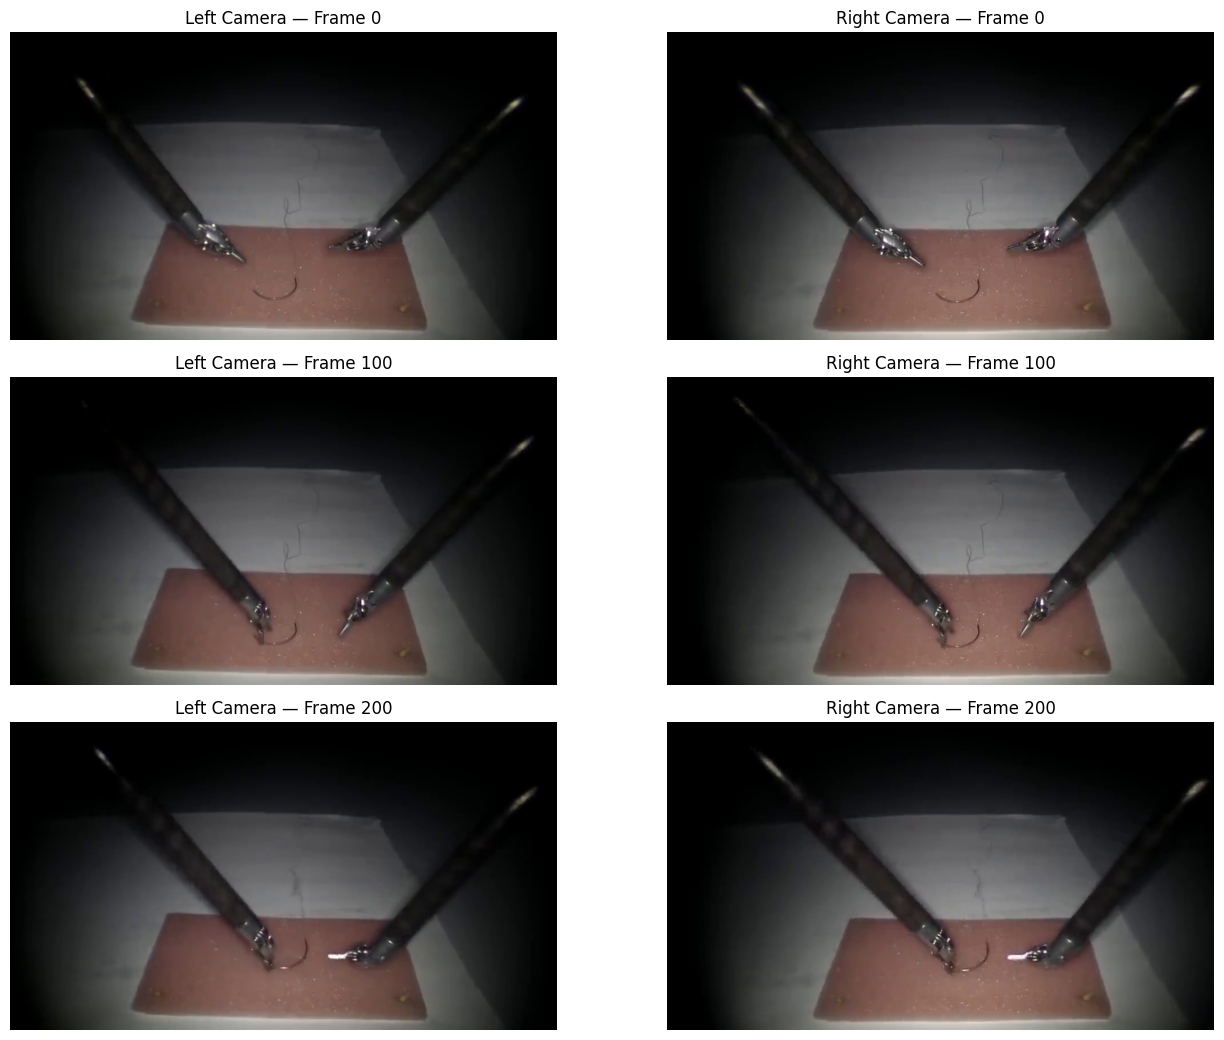

In [4]:
def read_frame(video_path, frame_idx):
    cap = cv2.VideoCapture(str(video_path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)

    success, frame = cap.read()
    cap.release()

    if not success:
        raise RuntimeError(f"Cannot read frame {frame_idx}")

    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


frame_indices = [0, 100, 200]

fig, axes = plt.subplots(
    len(frame_indices), 2,
    figsize=(14, 3.5 * len(frame_indices))
)

for i, frame_idx in enumerate(frame_indices):
    axes[i, 0].imshow(read_frame(left_video, frame_idx))
    axes[i, 0].set_title(f"Left Camera — Frame {frame_idx}")

    axes[i, 1].imshow(read_frame(right_video, frame_idx))
    axes[i, 1].set_title(f"Right Camera — Frame {frame_idx}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### 3. Initialize YOLO inference model

In [5]:
from ultralytics import YOLO

model = YOLO(str(MODEL_PATH))

print("Checkpoint:", MODEL_PATH.name)
print("Keypoint configuration:", model.model.kpt_shape)

Checkpoint: best.pt
Keypoint configuration: [2, 3]


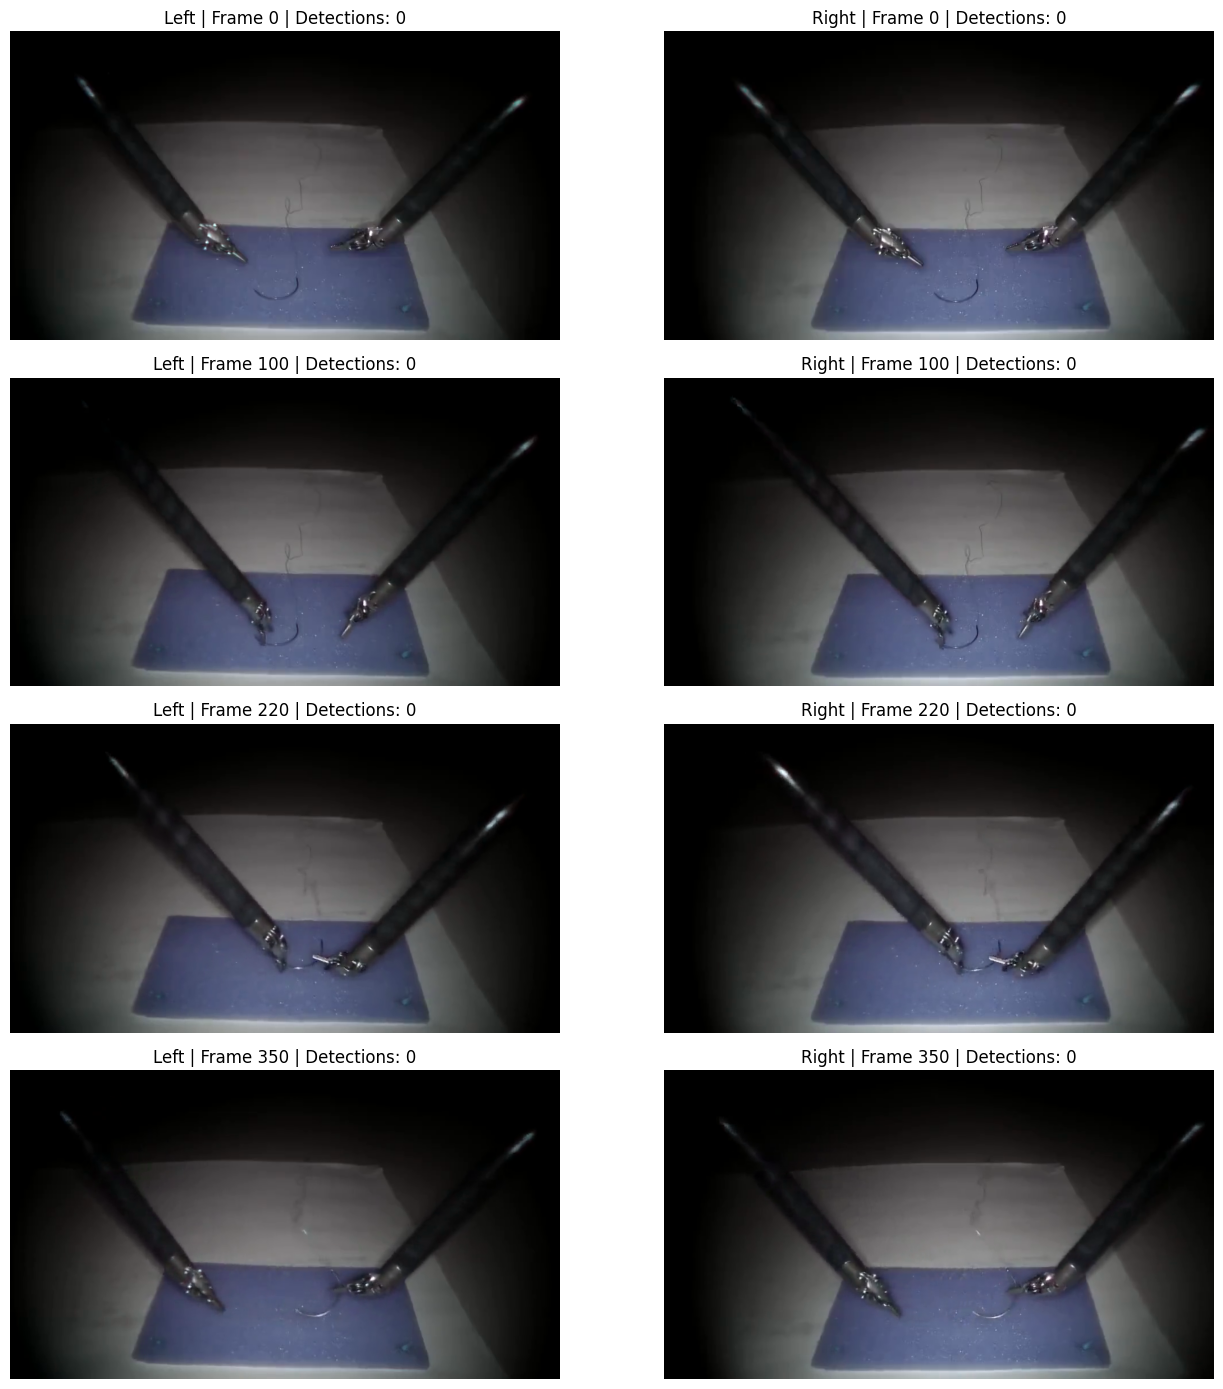

In [6]:
frame_indices = [0, 100, 220, 350]

fig, axes = plt.subplots(
    len(frame_indices), 2,
    figsize=(14, 3.5 * len(frame_indices))
)

for i, frame_idx in enumerate(frame_indices):
    for j, (camera_name, video_path) in enumerate([
        ("Left", left_video),
        ("Right", right_video)
    ]):
        frame_rgb = read_frame(video_path, frame_idx)

        result = model.predict(
            source=frame_rgb,
            conf=0.15,
            imgsz=640,
            verbose=False
        )[0]

        annotated_rgb = cv2.cvtColor(
            result.plot(),
            cv2.COLOR_BGR2RGB
        )

        axes[i, j].imshow(annotated_rgb)
        axes[i, j].set_title(
            f"{camera_name} | Frame {frame_idx} | "
            f"Detections: {len(result.boxes)}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

### 4. Data Analysis

In [7]:
import pandas as pd

thresholds = [0.15, 0.05, 0.01, 0.001]
frame_indices = [0, 100, 220, 350]

records = []

for camera_name, video_path in [
    ("Left", left_video),
    ("Right", right_video)
]:
    for frame_idx in frame_indices:

        frame_rgb = read_frame(video_path, frame_idx)

        for conf in thresholds:
            result = model.predict(
                source=frame_rgb,
                conf=conf,
                imgsz=640,
                verbose=False
            )[0]

            scores = result.boxes.conf.cpu().numpy()

            records.append({
                "camera": camera_name,
                "frame": frame_idx,
                "threshold": conf,
                "detections": len(scores),
                "max_confidence": (
                    float(scores.max()) if len(scores) else np.nan
                )
            })

threshold_results = pd.DataFrame(records)

display(
    threshold_results.pivot_table(
        index=["camera", "frame"],
        columns="threshold",
        values="detections",
        aggfunc="first"
    )
)

print("\nHighest confidence per frame at threshold 0.001:")

display(
    threshold_results[
        threshold_results["threshold"] == 0.001
    ][["camera", "frame", "detections", "max_confidence"]]
)

threshold     0.001  0.010  0.050  0.150
camera frame                            
Left   0          3      0      0      0
       100        3      1      0      0
       220        2      0      0      0
       350        3      1      0      0
Right  0          4      0      0      0
       100        4      1      0      0
       220        4      1      0      0
       350        3      1      0      0


Highest confidence per frame at threshold 0.001:


,camera,frame,detections,max_confidence
3,Left,0,3,0.008300
7,Left,100,3,0.025484
11,Left,220,2,0.004977
15,Left,350,3,0.033766
19,Right,0,4,0.007841
23,Right,100,4,0.014343
27,Right,220,4,0.036736
31,Right,350,3,0.022448


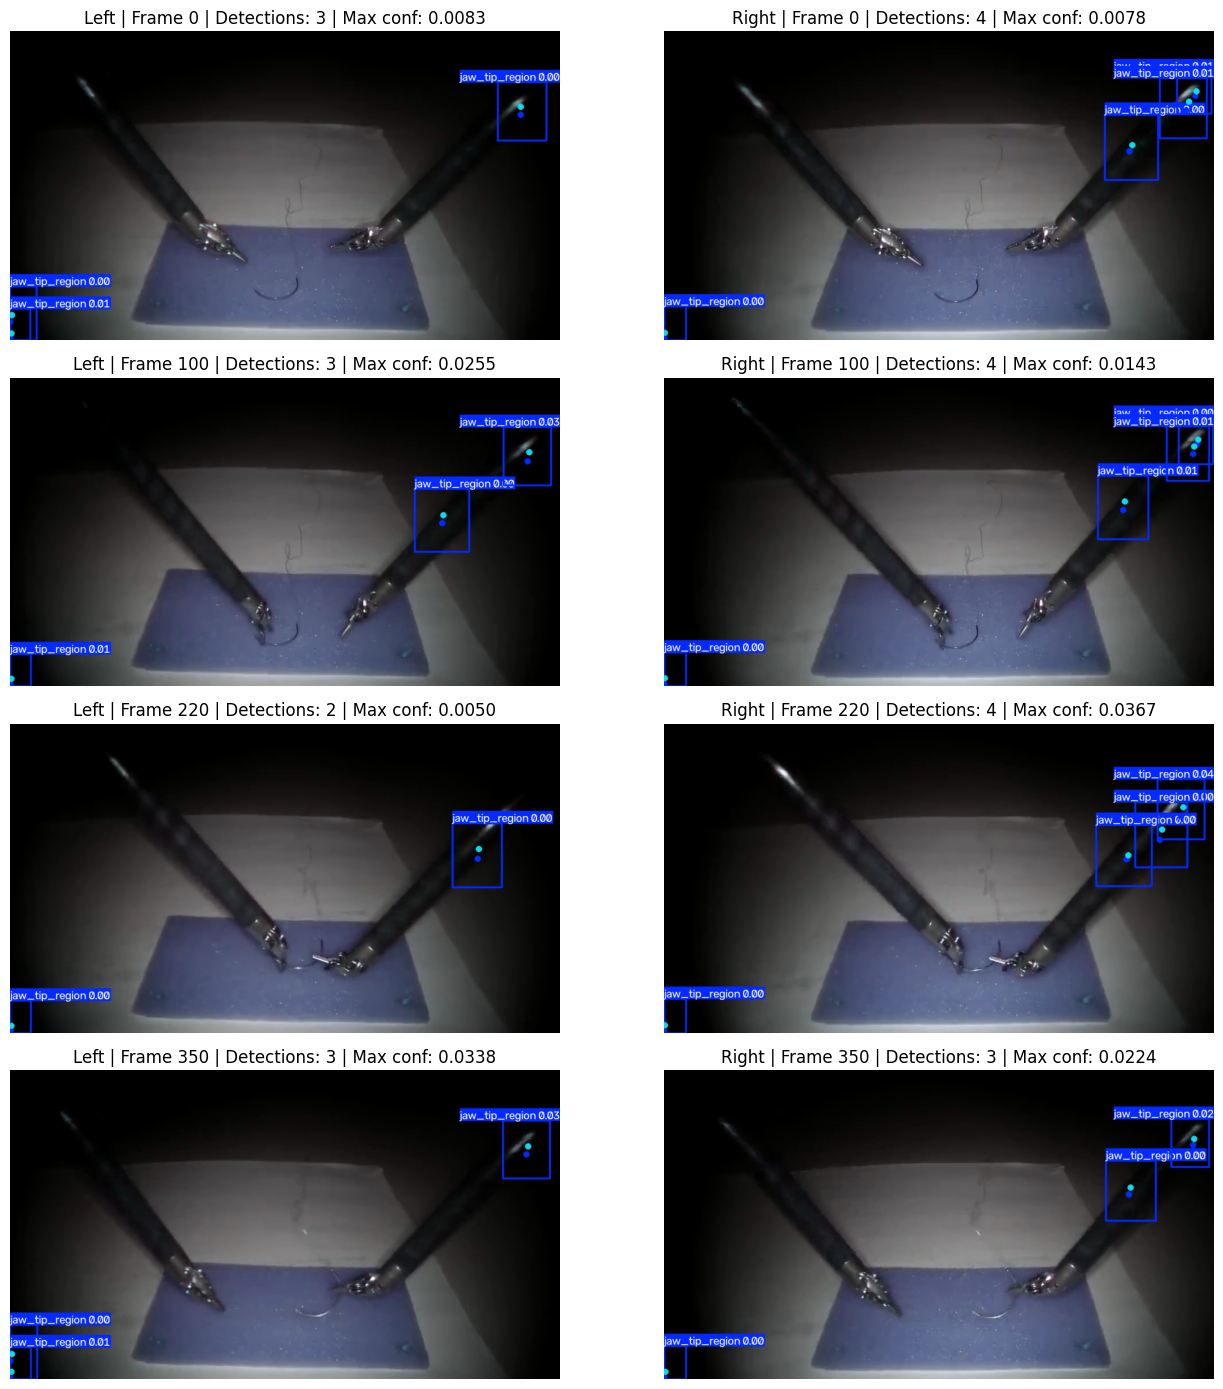

In [8]:
frame_indices = [0, 100, 220, 350]

fig, axes = plt.subplots(
    len(frame_indices), 2,
    figsize=(14, 3.5 * len(frame_indices))
)

for i, frame_idx in enumerate(frame_indices):
    for j, (camera_name, video_path) in enumerate([
        ("Left", left_video),
        ("Right", right_video)
    ]):

        frame_rgb = read_frame(video_path, frame_idx)

        result = model.predict(
            source=frame_rgb,
            conf=0.001,
            imgsz=640,
            verbose=False
        )[0]

        annotated_rgb = cv2.cvtColor(
            result.plot(),
            cv2.COLOR_BGR2RGB
        )

        scores = result.boxes.conf.cpu().numpy()

        axes[i, j].imshow(annotated_rgb)
        axes[i, j].set_title(
            f"{camera_name} | Frame {frame_idx} | "
            f"Detections: {len(scores)} | "
            f"Max conf: {scores.max():.4f}"
            if len(scores)
            else f"{camera_name} | Frame {frame_idx} | No detections"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

Validation images found: 42
Image: img_001005_raw.png
Detections: 2
Confidences: [    0.84616     0.83731]


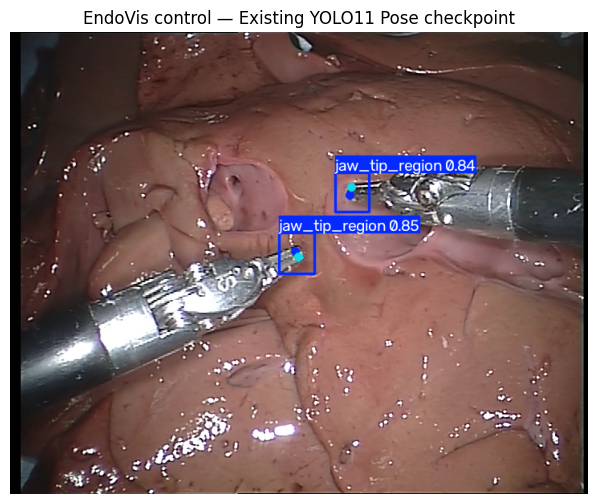

In [9]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

VAL_DIR = ROOT / "EndoVis_YOLO_Pose_Dataset1" / "images" / "val"

val_images = sorted(VAL_DIR.glob("*.png"))

if not val_images:
    val_images = sorted(VAL_DIR.glob("*.jpg"))

print("Validation images found:", len(val_images))

assert val_images, f"No validation images found in {VAL_DIR}"

sample_image = val_images[len(val_images) // 2]

result = model.predict(
    source=str(sample_image),
    conf=0.15,
    imgsz=640,
    verbose=False
)[0]

print("Image:", sample_image.name)
print("Detections:", len(result.boxes))
print("Confidences:", result.boxes.conf.cpu().numpy())

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("EndoVis control — Existing YOLO11 Pose checkpoint")
plt.show()

### 5. Summary

Overall Fail. CI proven not to be issue, datasets are too different.`